In [1]:
%pip install matplotlib-label-lines

In [2]:
%pip install tqdm

In [3]:
%pip install xgboost

In [4]:
%pip install scikit-learn

In [5]:
import os, warnings
import sys
import json
import traceback
from math import sqrt
import calendar
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from labellines import labelLine, labelLines
import xgboost
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

warnings.filterwarnings("ignore")

In [6]:
import matplotlib.pyplot as plt
plt.style.library["seaborn-whitegrid"] = (
    plt.style.library["seaborn-v0_8-whitegrid"]
)

In [7]:
DATASET_NAME = 'dehiwala_mc_2012-2018'
DAILY_WASTE_DATA_FILE_PATH = f'/content/{DATASET_NAME}.csv'

PREPROCESSING_CACHE_DIR_PATH = '/content/preprocessing_cache'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)

In [8]:
print("Results folder:", PREPROCESSING_CACHE_DIR_PATH)

Results folder: /content/preprocessing_cache


Import datasets.

In [9]:
df = pd.read_csv("dehiwala_mc_2012-2018.csv")

In [10]:
df.head(5)

,area,ticket_date,waste_type,net_weight_kg
0,Dehiwala MC,2012-01-01,Non Biodegradable,82270
1,Dehiwala MC,2012-01-02,Non Biodegradable,123010
2,Dehiwala MC,2012-01-03,Non Biodegradable,128330
3,Dehiwala MC,2012-01-04,Non Biodegradable,79430
4,Dehiwala MC,2012-01-05,Non Biodegradable,121320


In [11]:
df.shape

(3583, 4)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3583 entries, 0 to 3582
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   area           3583 non-null   object
 1   ticket_date    3583 non-null   object
 2   waste_type     3583 non-null   object
 3   net_weight_kg  3583 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 112.1+ KB


In [13]:
df.describe()

,net_weight_kg
count,3583.000000
mean,84242.126709
std,71086.506943
min,360.000000
25%,3450.000000
50%,98200.000000
75%,149215.000000
max,394870.000000


Check missing data

In [14]:
print(df['net_weight_kg'].isna().sum())

0


In [15]:
print(df['ticket_date'].duplicated().sum())


1458


In [16]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'])

In [17]:
print("Date range:")
print(df['ticket_date'].min(), "to", df['ticket_date'].max())

Date range:
2012-01-01 00:00:00 to 2018-12-31 00:00:00


In [18]:
expected_dates = pd.date_range(
    start=df['ticket_date'].min(),
    end=df['ticket_date'].max(),
    freq='D'
)

In [19]:
missing_dates = expected_dates.difference(df['ticket_date'])

In [20]:
print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 432
DatetimeIndex(['2013-05-04', '2014-10-16', '2014-10-17', '2014-10-18',
               '2014-10-19', '2014-10-20', '2014-10-21', '2014-10-22',
               '2014-10-23', '2014-10-24',
               ...
               '2018-07-01', '2018-08-01', '2018-09-01', '2018-10-24',
               '2018-11-02', '2018-12-01', '2018-12-13', '2018-12-14',
               '2018-12-22', '2018-12-23'],
              dtype='datetime64[ns]', length=432, freq=None)


In [21]:
zero_count = (df['net_weight_kg'] == 0).sum()

print("Number of zero values:", zero_count)
print("Percentage of zero values:",
      zero_count / len(df) * 100, "%")

Number of zero values: 0
Percentage of zero values: 0.0 %


checking outliers

In [22]:
Q1 = df['net_weight_kg'].quantile(0.25)
Q3 = df['net_weight_kg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['net_weight_kg'] < lower_limit) |
    (df['net_weight_kg'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

print(outliers[['ticket_date', 'net_weight_kg']])

Lower limit: -215197.5
Upper limit: 367862.5
Number of potential outliers: 1
     ticket_date  net_weight_kg
1903  2017-04-11         394870


In [23]:
daily_df = (
    df.groupby('ticket_date', as_index=False)['net_weight_kg']
    .sum()
)

daily_df['day_of_week'] = daily_df['ticket_date'].dt.day_name()
daily_df['month'] = daily_df['ticket_date'].dt.month
daily_df['year'] = daily_df['ticket_date'].dt.year

In [24]:
#Average waste by day of the week
weekday_avg = daily_df.groupby(
    'day_of_week'
)['net_weight_kg'].mean()

print(weekday_avg)

day_of_week
Friday       145681.749175
Monday       150327.737705
Saturday     145372.970297
Sunday       105472.333333
Thursday     147878.013029
Tuesday      150443.737705
Wednesday    148590.761589
Name: net_weight_kg, dtype: float64


In [25]:
#average waste by month
monthly_avg = daily_df.groupby(
    'month'
)['net_weight_kg'].mean()

print(monthly_avg)

month
1     138316.589595
2     141963.727811
3     143016.939891
4     140768.465909
5     146237.784091
6     145356.256983
7     144347.486339
8     126918.864865
9     140876.067416
10    142863.780488
11    143552.513966
12    150654.722222
Name: net_weight_kg, dtype: float64


Find the categories under waste_type.

In [26]:
waste_type_list = list(df['waste_type'].unique())

### Preprocess datasets.

In [27]:
# Get the year.
df['year'] = pd.DatetimeIndex(df['ticket_date']).year

In [28]:
# Get the month.
df['month'] = pd.DatetimeIndex(df['ticket_date']).month

In [29]:
df.columns

Index(['area', 'ticket_date', 'waste_type', 'net_weight_kg', 'year', 'month'], dtype='object')

### Filter the `ticket_date` and `net_weight_kg` columns.

In [30]:
df = df[['ticket_date', 'net_weight_kg']].groupby(['ticket_date']).agg('sum').reset_index()

### Convert `ticket_date` to UTC.

In [31]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'], utc=True)

### Extract 2012 to 2015

In [32]:
df = df.loc[~(df['ticket_date'].dt.year > 2015)]
df = df.reset_index(drop=True)

### Get dates between 2012-01-01 and 2015-12-31.

In [33]:
date_range_df = pd.date_range(start="2012-01-01", end="2015-12-31").to_frame(index=False, name='ticket_date')
date_range_df['ticket_date'] = pd.to_datetime(date_range_df['ticket_date'], utc=True)

### Add the complete date range to the df.

In [34]:
df = pd.merge(left=date_range_df, right=df, how='left', left_on='ticket_date', right_on='ticket_date')

### Convert `net_waste_kg` to numeric.

In [35]:
df['net_weight_kg'] = pd.to_numeric(df['net_weight_kg'])

### Available values

In [36]:
print(f'Available values: {df["net_weight_kg"].count()}')

Available values: 1433


### Missing values in net_weight_kg

In [37]:
missing_value_count = df["net_weight_kg"].isna().sum()
print(f'# missing values: {missing_value_count}')

# missing values: 28


In [38]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,28


In [39]:
# df['net_weight_kg'] = df['net_weight_kg'].interpolate(method='linear', limit_direction='both')
df = df.fillna(-200000)

In [40]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,0


In [41]:
df = df.set_index('ticket_date')

In [42]:
%pip install adtk

In [43]:
from adtk.data import validate_series
df = validate_series(df)
display(df)

,net_weight_kg
ticket_date,
2012-01-01 00:00:00+00:00,82270.0
2012-01-02 00:00:00+00:00,123010.0
2012-01-03 00:00:00+00:00,128330.0
2012-01-04 00:00:00+00:00,79430.0
2012-01-05 00:00:00+00:00,121320.0
...,...
2015-12-27 00:00:00+00:00,115540.0
2015-12-28 00:00:00+00:00,171530.0
2015-12-29 00:00:00+00:00,183330.0


[<Axes: >]

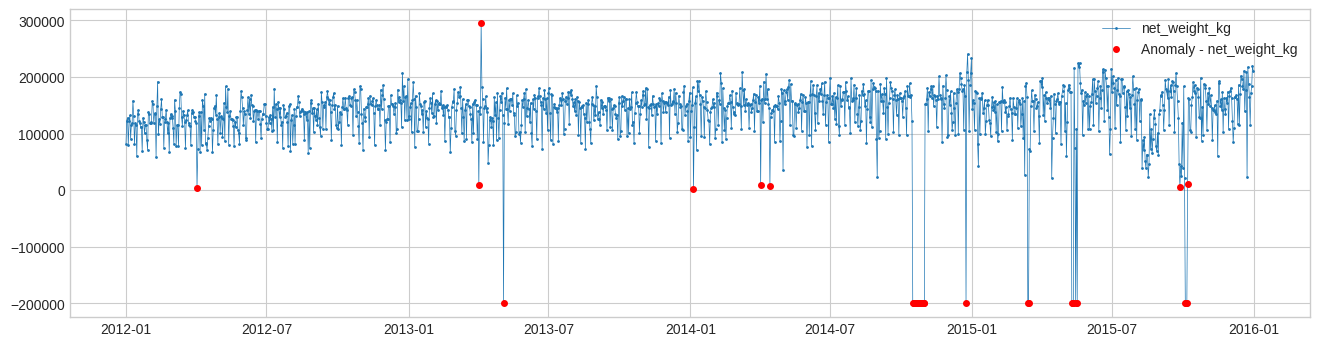

In [44]:
from adtk.detector import SeasonalAD
from adtk.visualization import plot

# Create the seasonal anomaly detector
seasonal_ad = SeasonalAD()

# Detect anomalies in the time-series data
anomalies = seasonal_ad.fit_detect(df)

# Plot the original data and highlight anomalies
plot(
    df,
    anomaly=anomalies,
    anomaly_color="red",
    anomaly_tag="marker"
)

### Remove outliers

In [45]:
anomalies_mask = np.array(anomalies.reset_index()['net_weight_kg'].tolist())

In [46]:
print(f'outliers: {anomalies_mask.sum() - missing_value_count}')

#original - 29

outliers: 8


In [47]:
df['net_weight_kg'] = df['net_weight_kg'].iloc[~anomalies_mask]

In [48]:
df = df.reset_index()

### Set (Saturdays, Sundays) detected as outliers to 0

In [49]:
df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0

### Set value for 2001-01-01 (Monday)

In [50]:
df.at[0, 'net_weight_kg'] = df.head(5)['net_weight_kg'].mean()

In [51]:
df.head(5)

,ticket_date,net_weight_kg
0,2012-01-01 00:00:00+00:00,90418.0
1,2012-01-02 00:00:00+00:00,123010.0
2,2012-01-03 00:00:00+00:00,128330.0
3,2012-01-04 00:00:00+00:00,79430.0
4,2012-01-05 00:00:00+00:00,121320.0


In [52]:
print("Blank days (NaN)         :", df["net_weight_kg"].isna().sum())
print("Values below 0 (want 0)  :", (df["net_weight_kg"] < 0).sum())

Blank days (NaN)         : 24
Values below 0 (want 0)  : 0


### Waste Data Visualization

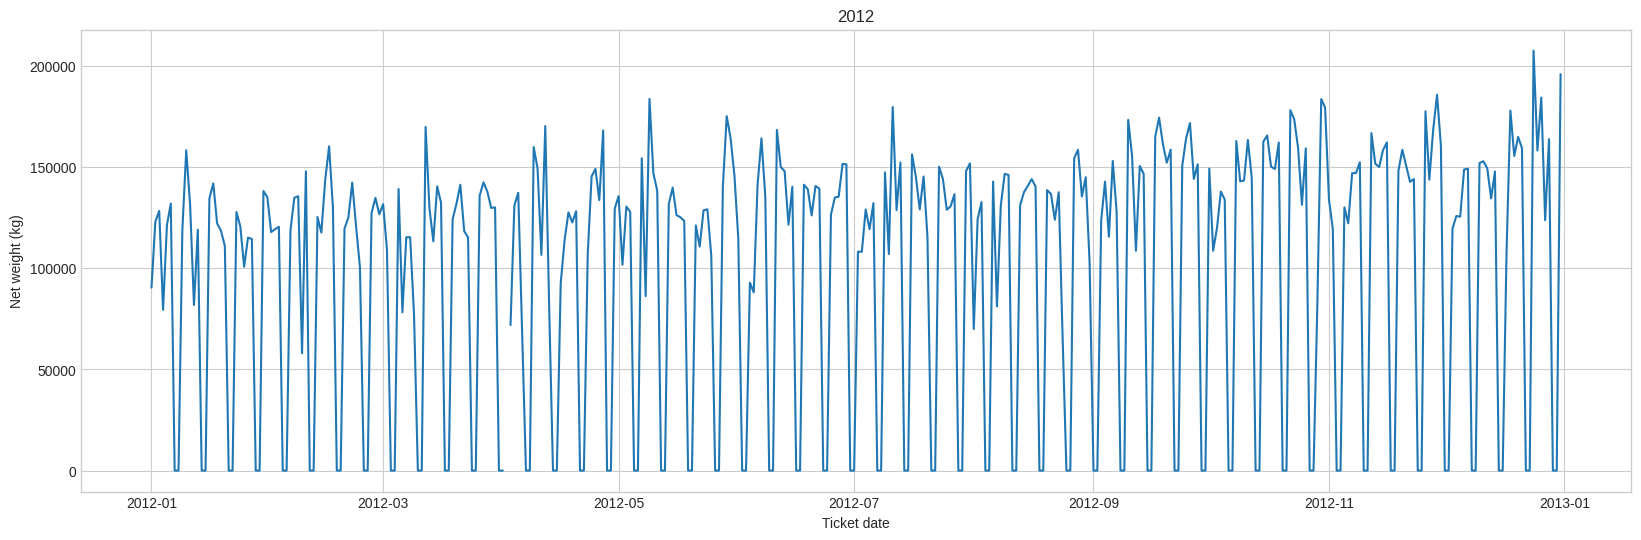

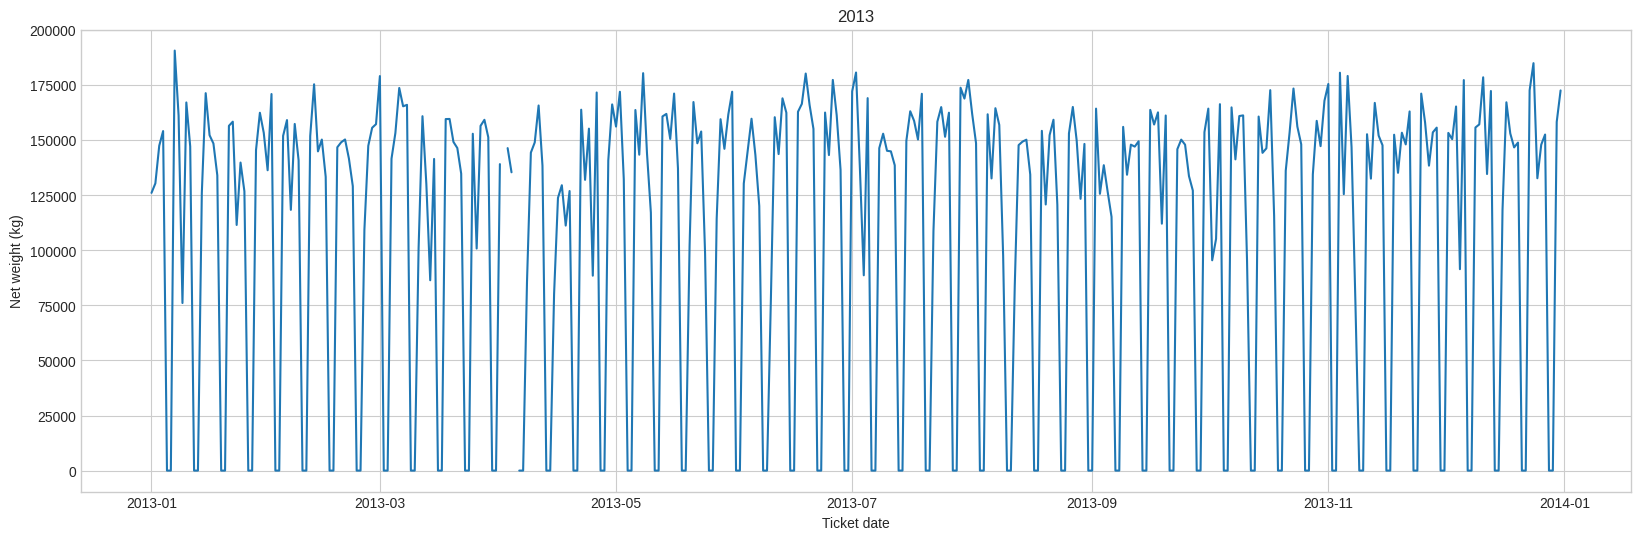

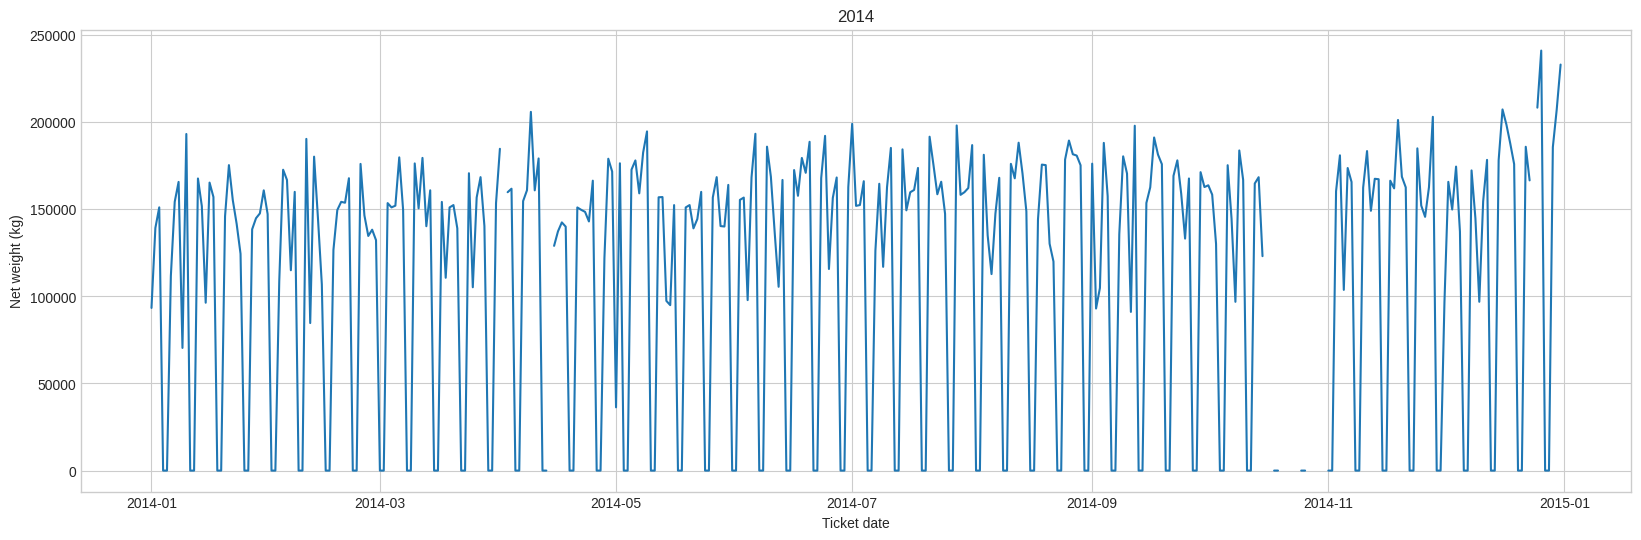

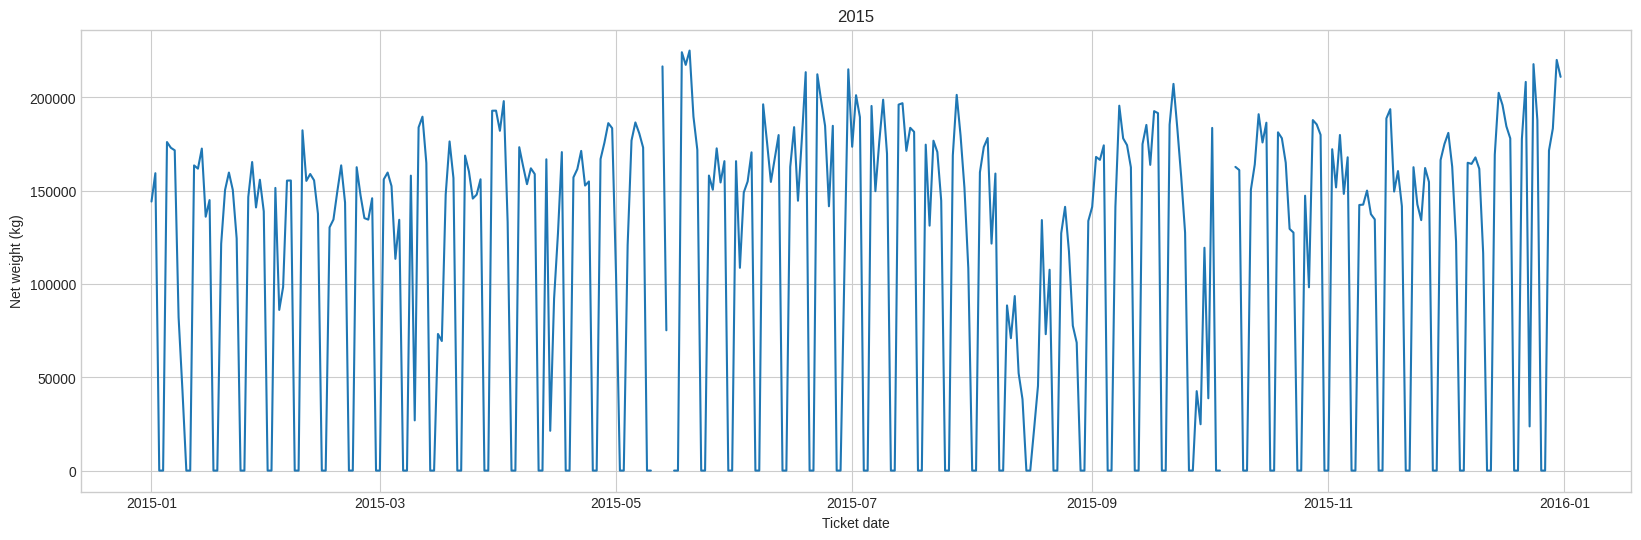

In [53]:
for year in range(2012, 2016):
    x = df[df['ticket_date'].dt.year == year]['ticket_date'].tolist()
    y = df[df['ticket_date'].dt.year == year]['net_weight_kg'].tolist()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)

    plt.plot(x, y)
    plt.title('{}'.format(year))
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.show()

### best model selection

Hyperparameter tuning for XGBoost

In [54]:
lag_count_list = [42, 360, 150, 120, 49, 14, 90]
estimator_count_list = [10, 100, 1000]
max_depth_list = [7, 3, 8 , 9, 4, 6]
subsample_list = [0.6, 0.9, 0.7, 0.8]
eta_list = [0.01, 0.3, 0.1]

n_iter = (len(lag_count_list) * len(estimator_count_list) * len(max_depth_list)
          * len(subsample_list) * len(eta_list))
print("Total configurations:", n_iter)

Total configurations: 1512


In [55]:
def evaluate(lag_count, estimator_count, max_depth, subsample, eta):

    df_temp = df.copy()

    for i in range(1, lag_count + 1):
        df_temp[f'net_weight_kg_lag_{i}'] = df_temp['net_weight_kg'].shift(i)

    lag_columns = [f'net_weight_kg_lag_{i}' for i in range(1, lag_count + 1)]
    df_temp = df_temp.dropna(subset=['net_weight_kg'] + lag_columns)

    X = df_temp.drop(columns=['ticket_date', 'net_weight_kg'])
    y = df_temp['net_weight_kg']

    split_index = int(len(df_temp) * 0.8)            
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = xgboost.XGBRegressor(
        n_estimators=estimator_count, random_state=0, max_depth=max_depth,
        subsample=subsample, learning_rate=eta,
        objective='reg:squarederror', n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return sqrt(mean_squared_error(y_test, y_pred))

In [56]:
DATASET_NAME = "Dehiwala"
PREPROCESSING_CACHE_DIR_PATH = f'preprocessing_cache_{DATASET_NAME}_full'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)
os.makedirs("grid_search_results", exist_ok=True)

results, errors = [], []

with tqdm(total=n_iter, desc="Grid Search") as pbar:
    for lag_count in lag_count_list:
        for estimator_count in estimator_count_list:
            for max_depth in max_depth_list:
                for subsample in subsample_list:
                    for eta in eta_list:
                        filename = (f'lag-{lag_count}_est-{estimator_count}_dpt-{max_depth}'
                                    f'_subsmp-{subsample}_eta-{eta}.json')
                        file_path = os.path.join(PREPROCESSING_CACHE_DIR_PATH, filename)
                        try:
                            if os.path.exists(file_path):
                                with open(file_path, 'r') as f:
                                    summary = json.load(f)
                            else:
                                rmse = evaluate(lag_count, estimator_count, max_depth, subsample, eta)
                                summary = {'rmse': float(rmse), 'lag_count': lag_count,
                                           'estimator_count': estimator_count, 'max_depth': max_depth,
                                           'subsample': subsample, 'eta': eta}
                                with open(file_path, 'w') as f:
                                    json.dump(summary, f, indent=4)
                            results.append(summary)
                        except Exception as e:
                            errors.append({'filename': filename, 'error': str(e)})
                        finally:
                            pbar.update(1)

print("Successful results:", len(results), "| Failed:", len(errors))
if errors: print(errors[:3])

results_df = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
display(results_df)
results_df.to_csv("all_grid_search_results_Dehiwala.csv", index=False)    # CHANGED: local path

Grid Search:   0%|          | 0/1512 [00:00<?, ?it/s]

Successful results: 1512 | Failed: 0


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,22678.317094,150,100,3,0.9,0.10
1,22851.921346,150,1000,7,0.9,0.01
2,23019.704455,150,1000,4,0.7,0.01
3,23124.581596,150,1000,3,0.8,0.01
4,23129.092037,150,1000,3,0.9,0.10
...,...,...,...,...,...,...
1507,109846.929688,360,10,6,0.6,0.01
1508,109846.929688,360,10,8,0.6,0.01
1509,109846.929688,360,10,4,0.6,0.01
1510,109846.929688,360,10,3,0.6,0.01


In [57]:
# all results, best (lowest RMSE) first
results_df = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
print("Top 10 settings")
display(results_df.head(10))

Top 10 settings


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,22678.317094,150,100,3,0.9,0.10
1,22851.921346,150,1000,7,0.9,0.01
2,23019.704455,150,1000,4,0.7,0.01
3,23124.581596,150,1000,3,0.8,0.01
4,23129.092037,150,1000,3,0.9,0.10
5,23206.185266,150,1000,9,0.9,0.01
6,23251.000820,150,100,3,0.6,0.10
7,23311.302361,150,1000,8,0.9,0.01
8,23343.096737,150,1000,6,0.9,0.01
9,23351.493136,150,1000,3,0.7,0.01


In [58]:
# best setting for each lag count
best_per_lag = results_df.loc[results_df.groupby('lag_count')['rmse'].idxmin()].sort_values('rmse')
print("Best setting for each lag count")
display(best_per_lag)

def to_params(row):
    return {'rmse': float(row['rmse']), 'lag_count': int(row['lag_count']),
            'estimator_count': int(row['estimator_count']), 'max_depth': int(row['max_depth']),
            'subsample': float(row['subsample']), 'eta': float(row['eta'])}

Best setting for each lag count


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,22678.317094,150,100,3,0.9,0.10
144,31994.331535,120,100,3,0.6,0.10
302,37710.587715,14,10,4,0.7,0.30
320,38335.863834,49,10,3,0.9,0.30
335,38640.663045,42,1000,3,0.7,0.01
393,39222.667182,90,10,3,0.9,0.30
951,45996.093750,360,1000,8,0.9,0.30


In [59]:
# 1) optimum-lag model = the lowest RMSE of all settings
optimum_lag_model_params = to_params(best_per_lag.iloc[0])

In [60]:

# 2) minimum-lag model = the lowest RMSE among lag counts that fit before the first blank day
null_rows = df.index[df['net_weight_kg'].isna()]
first_null_index = int(null_rows[0]) if len(null_rows) > 0 else len(df)
print("First blank row index:", first_null_index)

short_ok = best_per_lag[best_per_lag['lag_count'] < first_null_index]
if len(short_ok) == 0:
    raise ValueError(f"No lag count below {first_null_index} was tested. "
                     "Add a smaller lag (for example 7 or 14) to lag_count_list and run the search again.")
minimum_lag_model_params = to_params(short_ok.iloc[0])

print("\nOptimum lag model:", optimum_lag_model_params)
print("Minimum lag model:", minimum_lag_model_params)

First blank row index: 92

Optimum lag model: {'rmse': 22678.31709409772, 'lag_count': 150, 'estimator_count': 100, 'max_depth': 3, 'subsample': 0.9, 'eta': 0.1}
Minimum lag model: {'rmse': 37710.58771502944, 'lag_count': 14, 'estimator_count': 10, 'max_depth': 4, 'subsample': 0.7, 'eta': 0.3}


In [61]:
def evaluate_forecast(actual, predicted, plot_title=None):
    rmse = sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    try:
        mape = mean_absolute_percentage_error(actual, predicted)
    except Exception:
        mape = None
    print('RMSE:', rmse, '| MAE:', mae, '| MAPE:', mape)

    plt.figure(figsize=(20, 6), dpi=100)
    plt.plot(np.asarray(actual))
    plt.plot(np.asarray(predicted))
    if plot_title:                                  
        plt.title(plot_title)
    plt.show()
    return rmse, mae, mape

RMSE: 22678.316692382617 | MAE: 16319.25 | MAPE: 1.894112051056345e+18


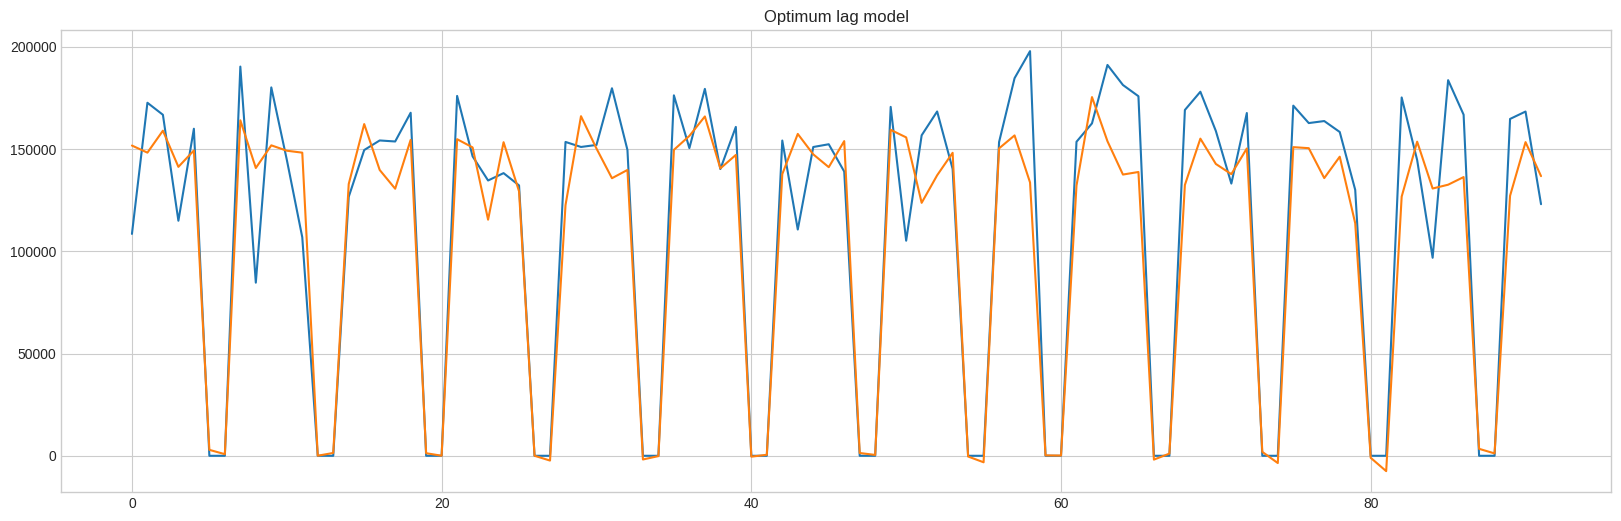

Baseline RMSE (same weekday last week): 29832.843004633844


In [62]:
df_temp = df.copy()                                        

for i in range(1, optimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
df_temp = df_temp.dropna()
del df_temp['ticket_date']

X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

cut = int(len(X) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y[:cut], y[cut:]

model_optimum = xgboost.XGBRegressor(
    n_estimators=optimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=optimum_lag_model_params['max_depth'],
    subsample=optimum_lag_model_params['subsample'],
    eta=optimum_lag_model_params['eta'])
model_optimum.fit(X_train, y_train)
y_pred = model_optimum.predict(X_test)

evaluate_forecast(y_test, y_pred, "Optimum lag model")

if "net_weight_kg_lag_7" in X_test.columns:
    base = X_test["net_weight_kg_lag_7"].to_numpy()
    print("Baseline RMSE (same weekday last week):", sqrt(mean_squared_error(y_test, base)))
else:
    print("Baseline skipped: this model uses fewer than 7 lags.")

RMSE: 37710.58800920506 | MAE: 25003.904296875 | MAPE: 3.9958976593437655e+18


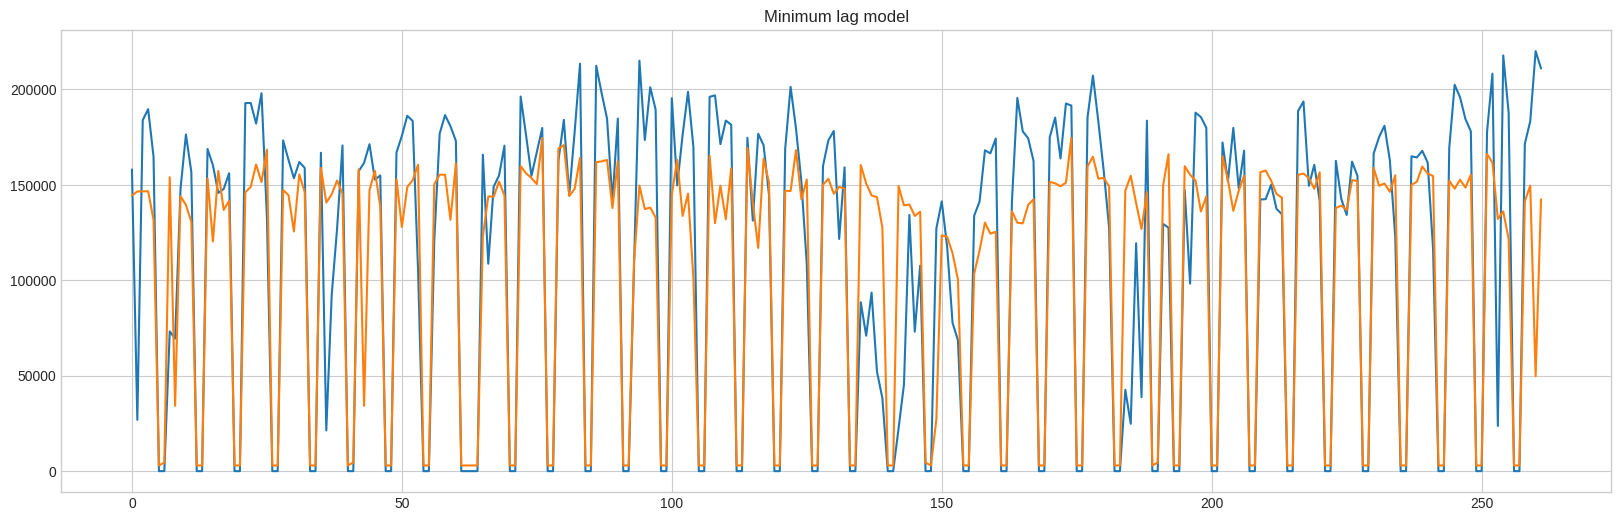

Baseline RMSE (same weekday last week): 43446.472568275945


In [63]:
df_temp = df.copy()

for i in range(1, minimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
df_temp = df_temp.dropna()
del df_temp['ticket_date']

X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

cut = int(len(X) * 0.8)                                     
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y[:cut], y[cut:]

model_minimum = xgboost.XGBRegressor(
    n_estimators=minimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=minimum_lag_model_params['max_depth'],
    subsample=minimum_lag_model_params['subsample'],
    eta=minimum_lag_model_params['eta'])
model_minimum.fit(X_train, y_train)
y_pred = model_minimum.predict(X_test)

evaluate_forecast(y_test, y_pred, "Minimum lag model")

if "net_weight_kg_lag_7" in X_test.columns:
    base = X_test["net_weight_kg_lag_7"].to_numpy()
    print("Baseline RMSE (same weekday last week):", sqrt(mean_squared_error(y_test, base)))
else:
    print("Baseline skipped: this model uses fewer than 7 lags.")

In [64]:
df['predicted_net_weight_kg'] = np.nan

for index in df.index:
    if pd.isnull(df.at[index, 'net_weight_kg']):

        if index > optimum_lag_model_params['lag_count']:
            lag = optimum_lag_model_params['lag_count']
            model = model_optimum
        else:
            lag = minimum_lag_model_params['lag_count']
            model = model_minimum

        previous_values = df['net_weight_kg'].iloc[index - lag:index].tolist()[::-1]
        column_list = ['net_weight_kg_lag_{}'.format(i) for i in range(1, lag + 1)]
        previous_df = pd.DataFrame([previous_values], columns=column_list)

        value = float(max(model.predict(previous_df)[0], 0.0)) 
        df.at[index, 'net_weight_kg'] = value
        df.at[index, 'predicted_net_weight_kg'] = value

In [65]:
n_imputed = int(df["predicted_net_weight_kg"].count())
print(f"Imputed values: {n_imputed}")
print(f"Percentage of imputed values: {n_imputed / len(df) * 100:.2f} %")  
print(f"Mean of imputed values: {df['predicted_net_weight_kg'].mean()}")
print(f"SD of imputed values: {df['predicted_net_weight_kg'].std()}")
print("Blanks left:", df['net_weight_kg'].isna().sum())                    

Imputed values: 24
Percentage of imputed values: 1.64 %
Mean of imputed values: 136045.16707356772
SD of imputed values: 31316.012937048607
Blanks left: 0


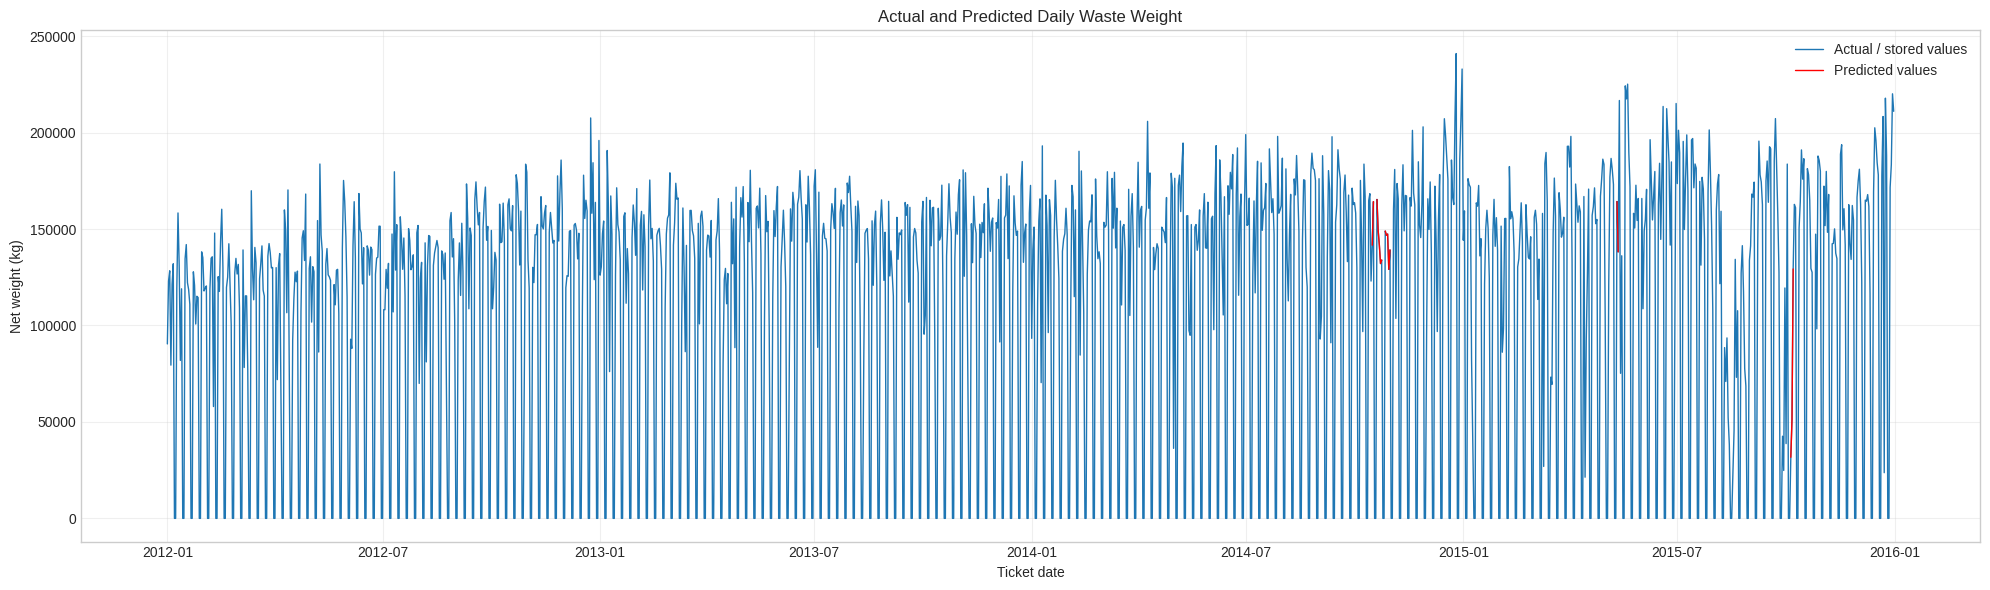

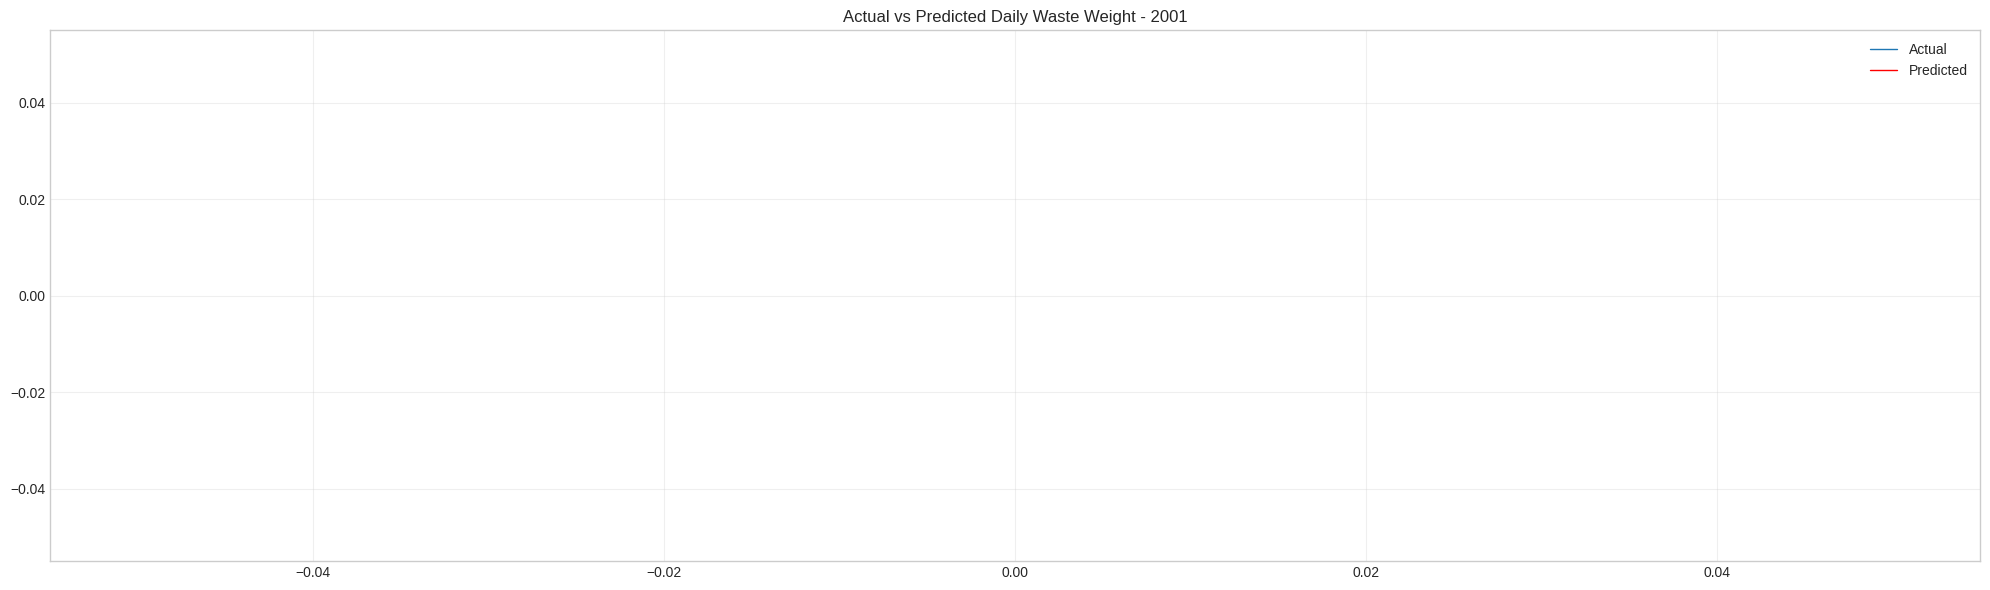

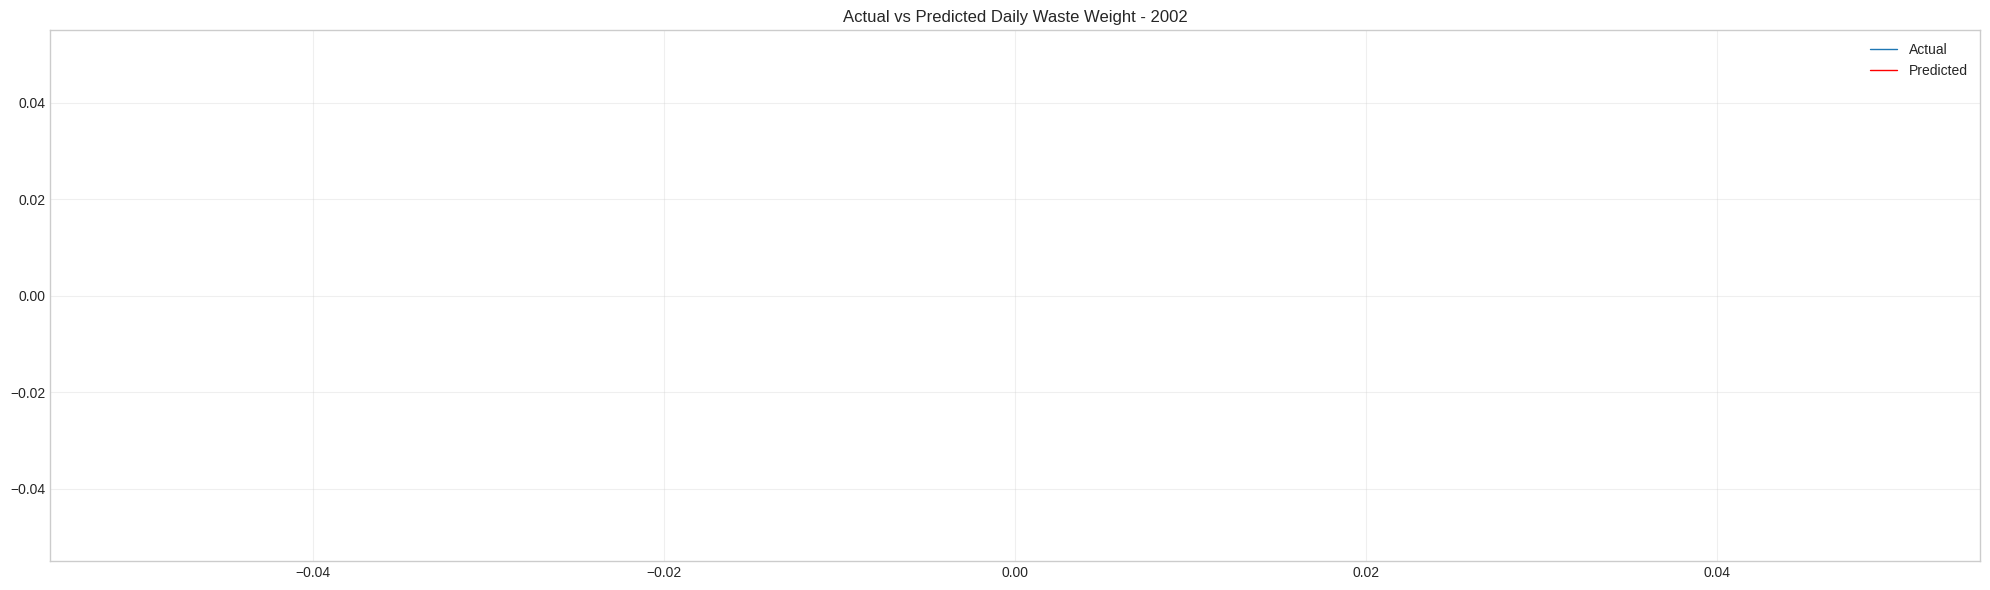

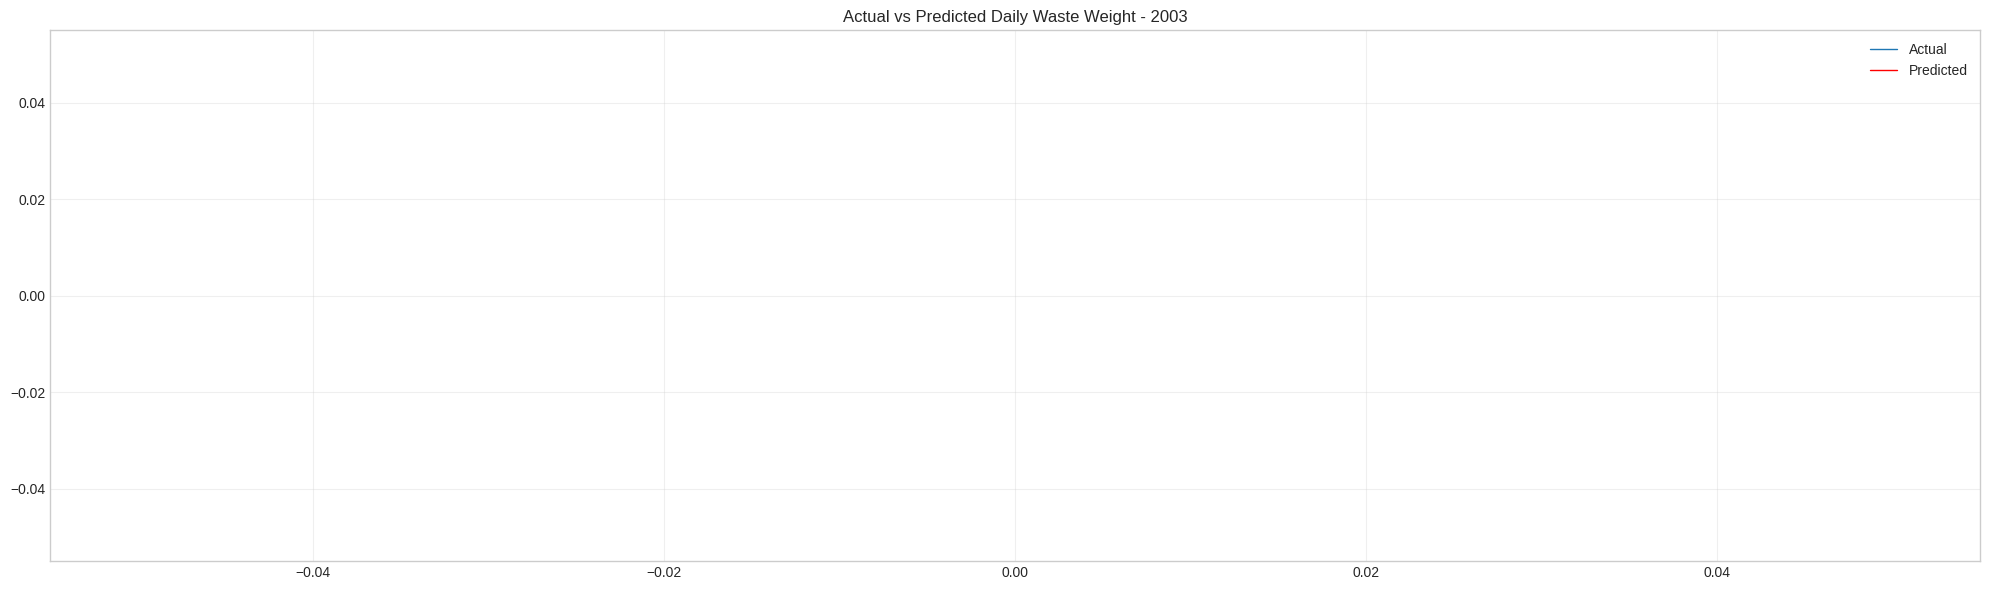

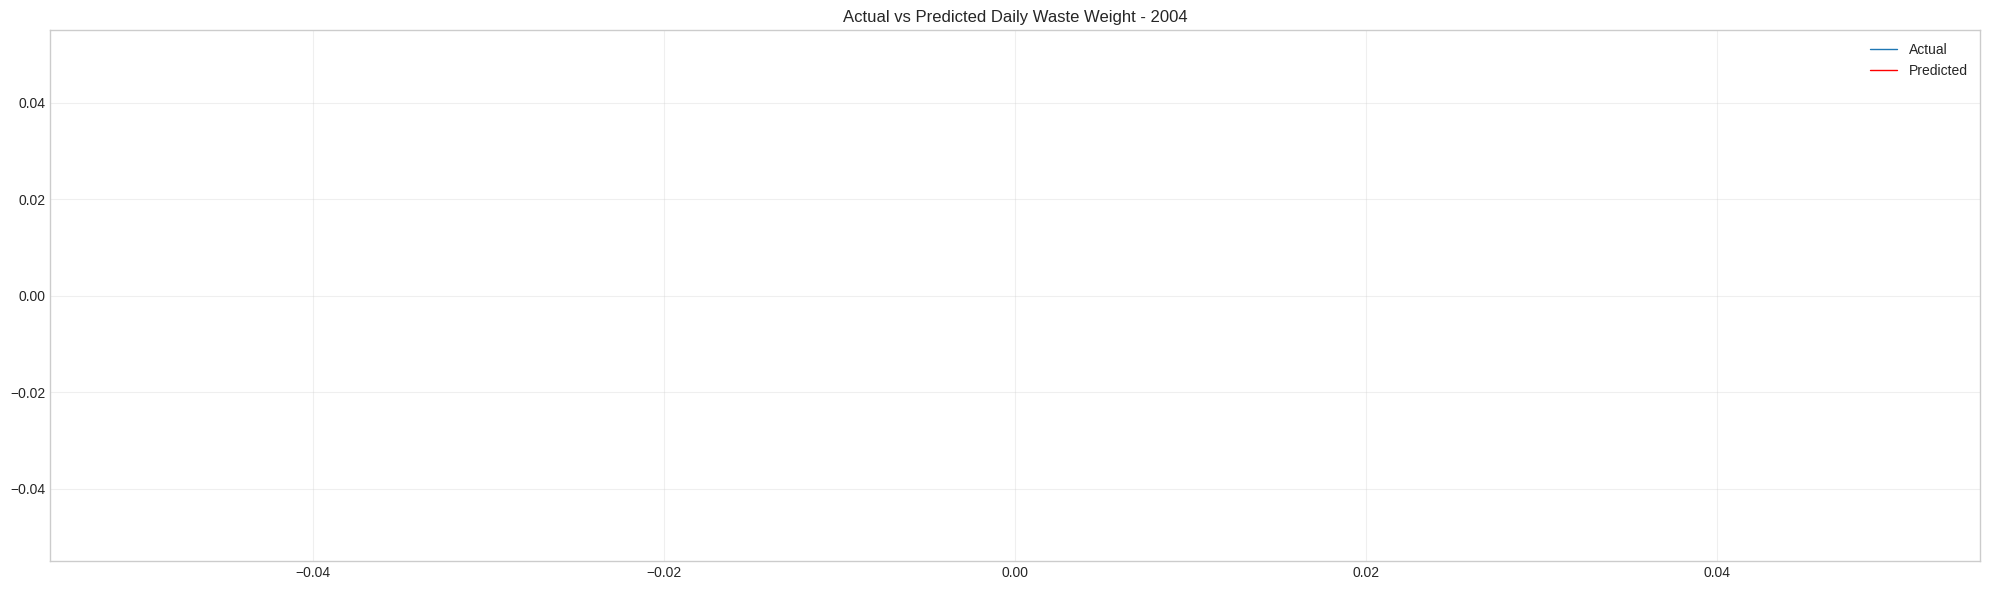

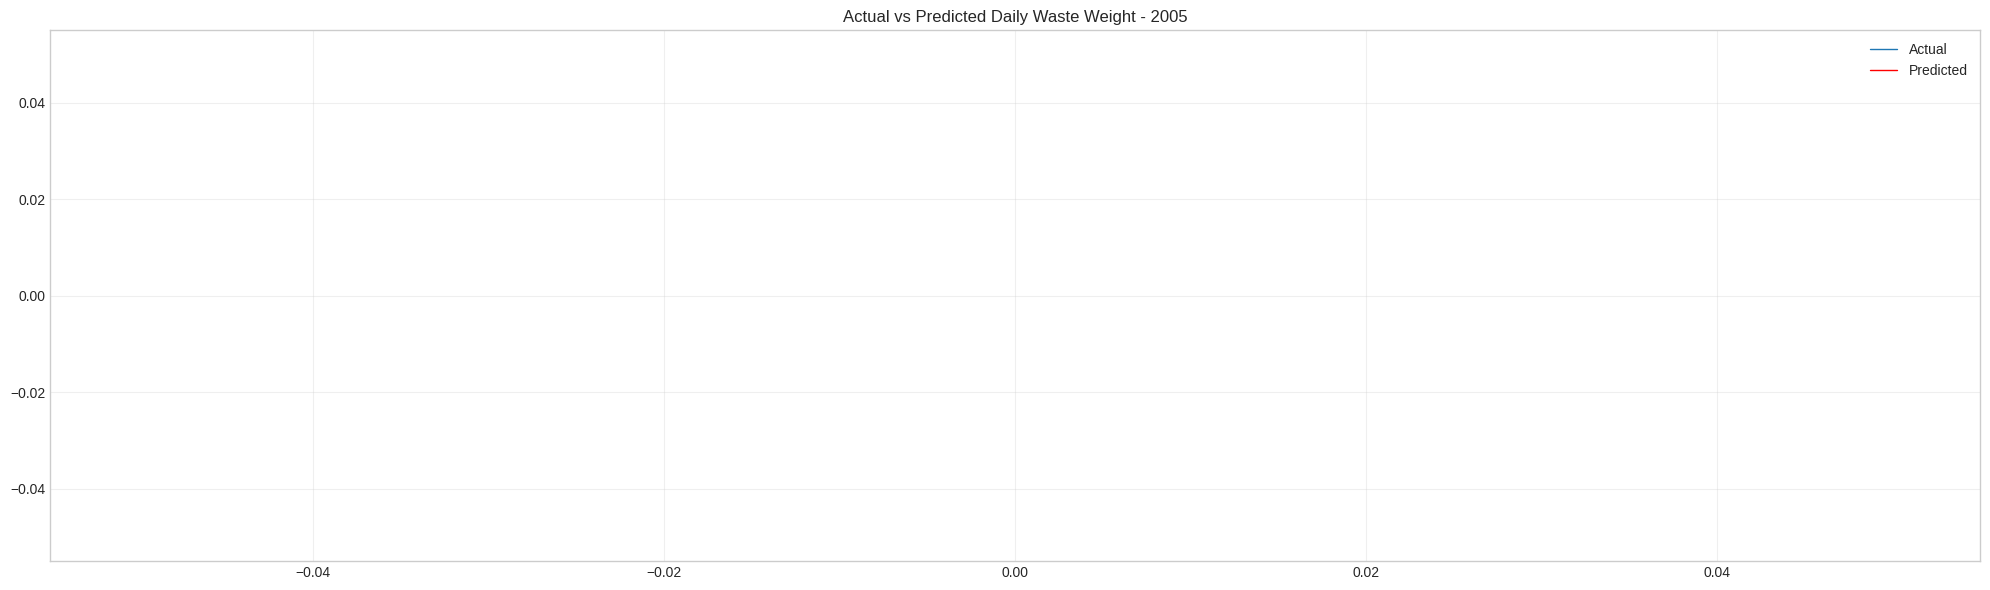

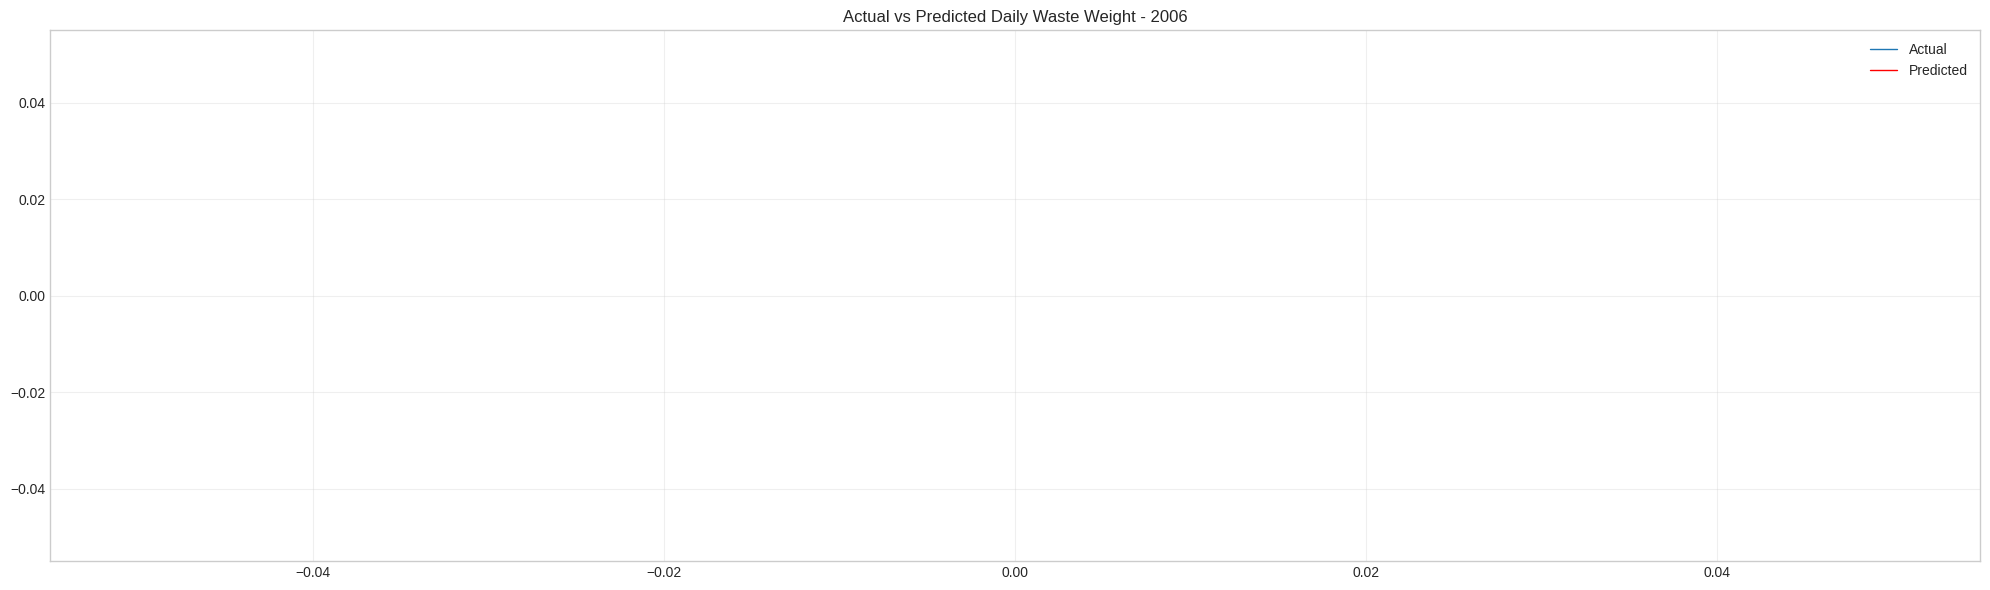

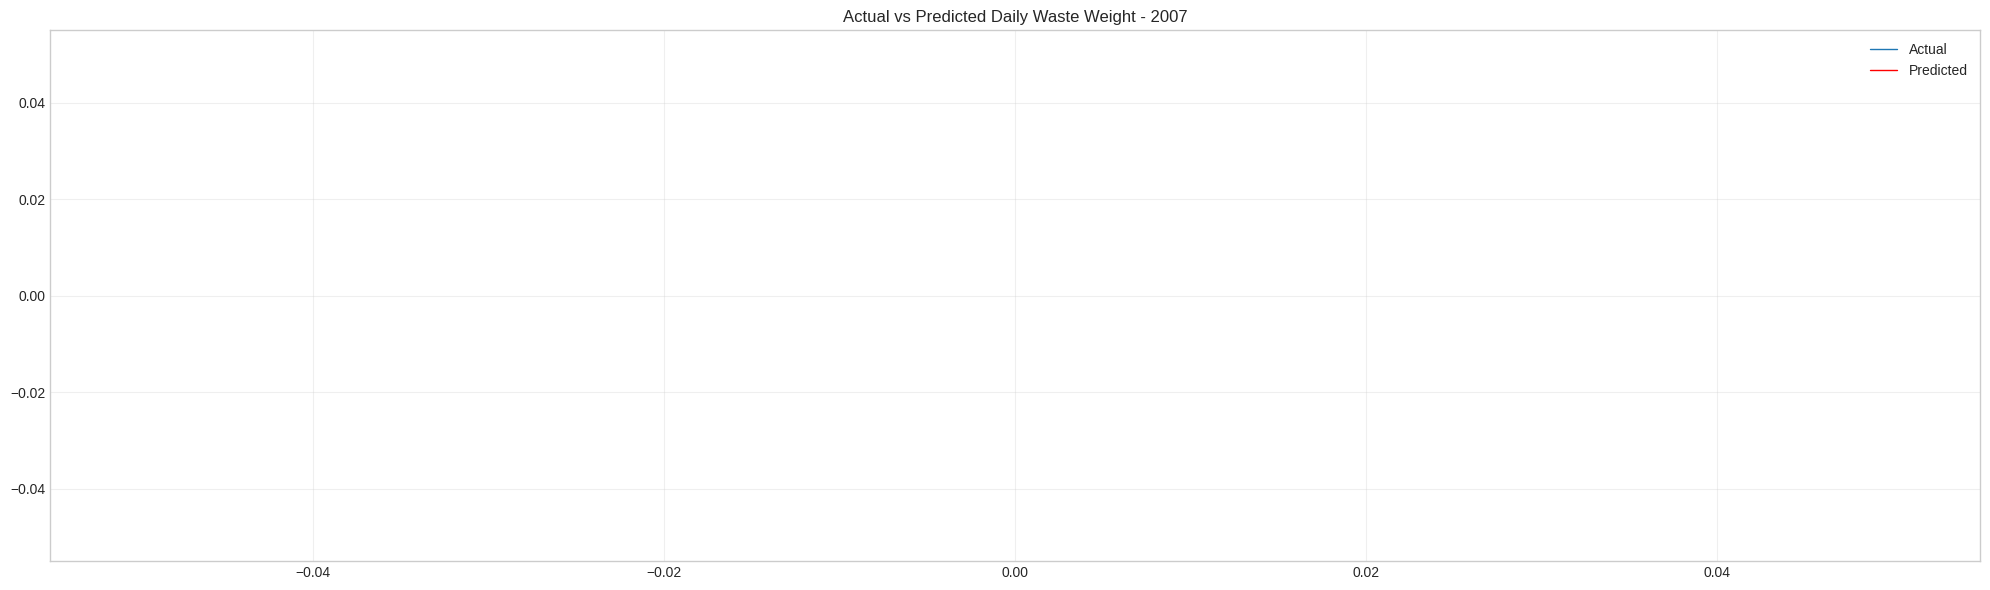

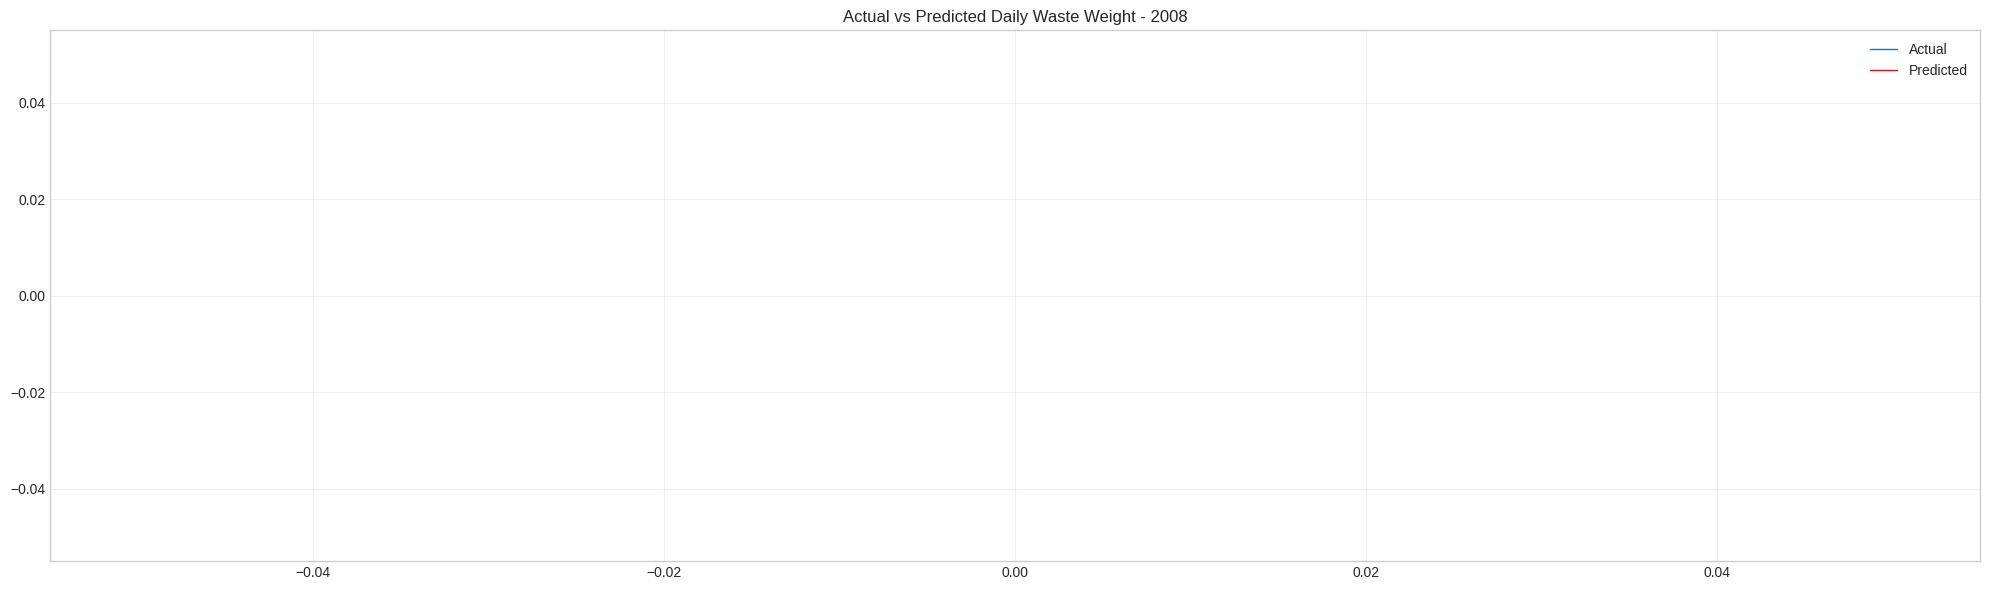

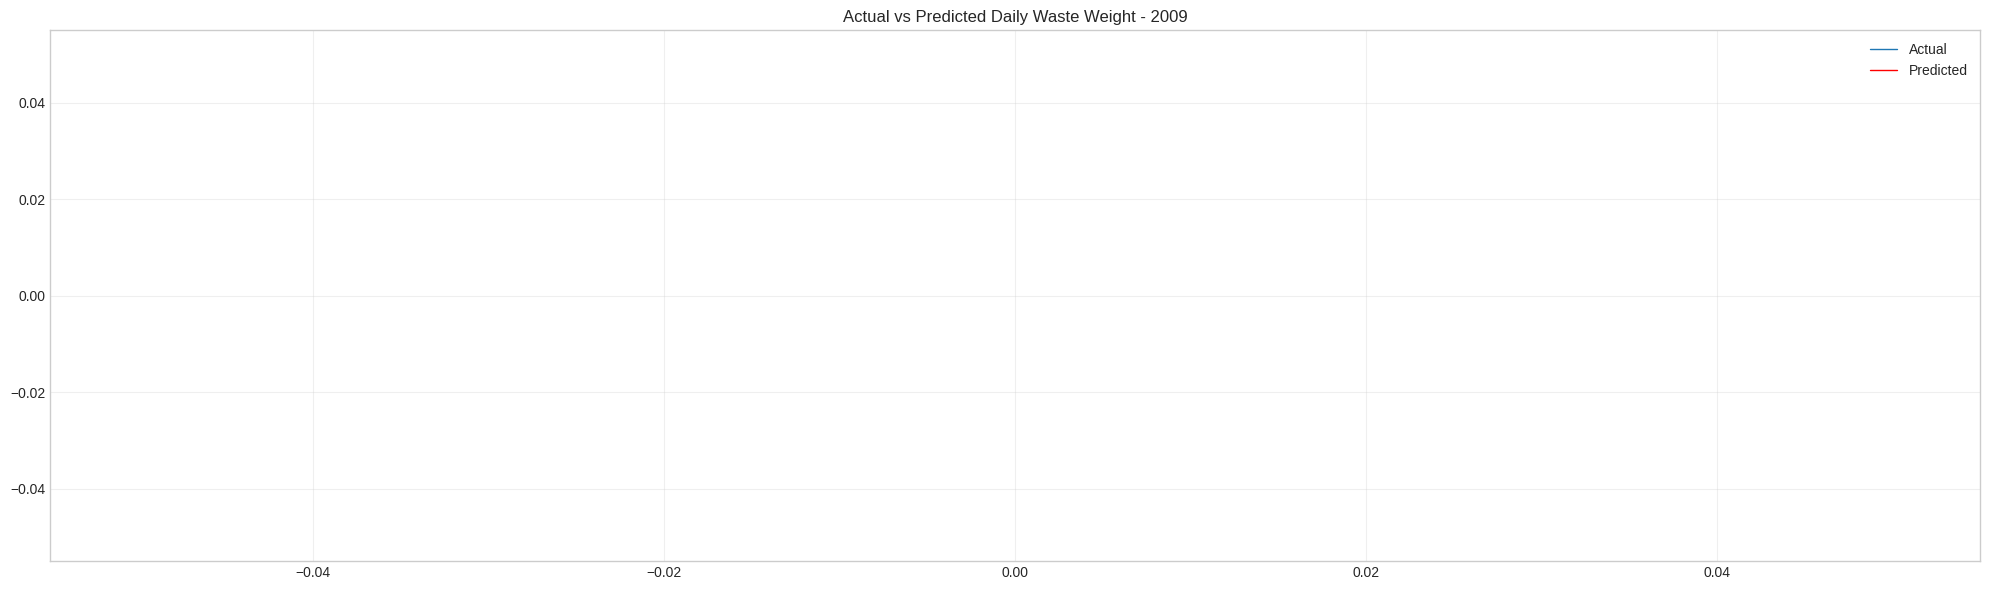

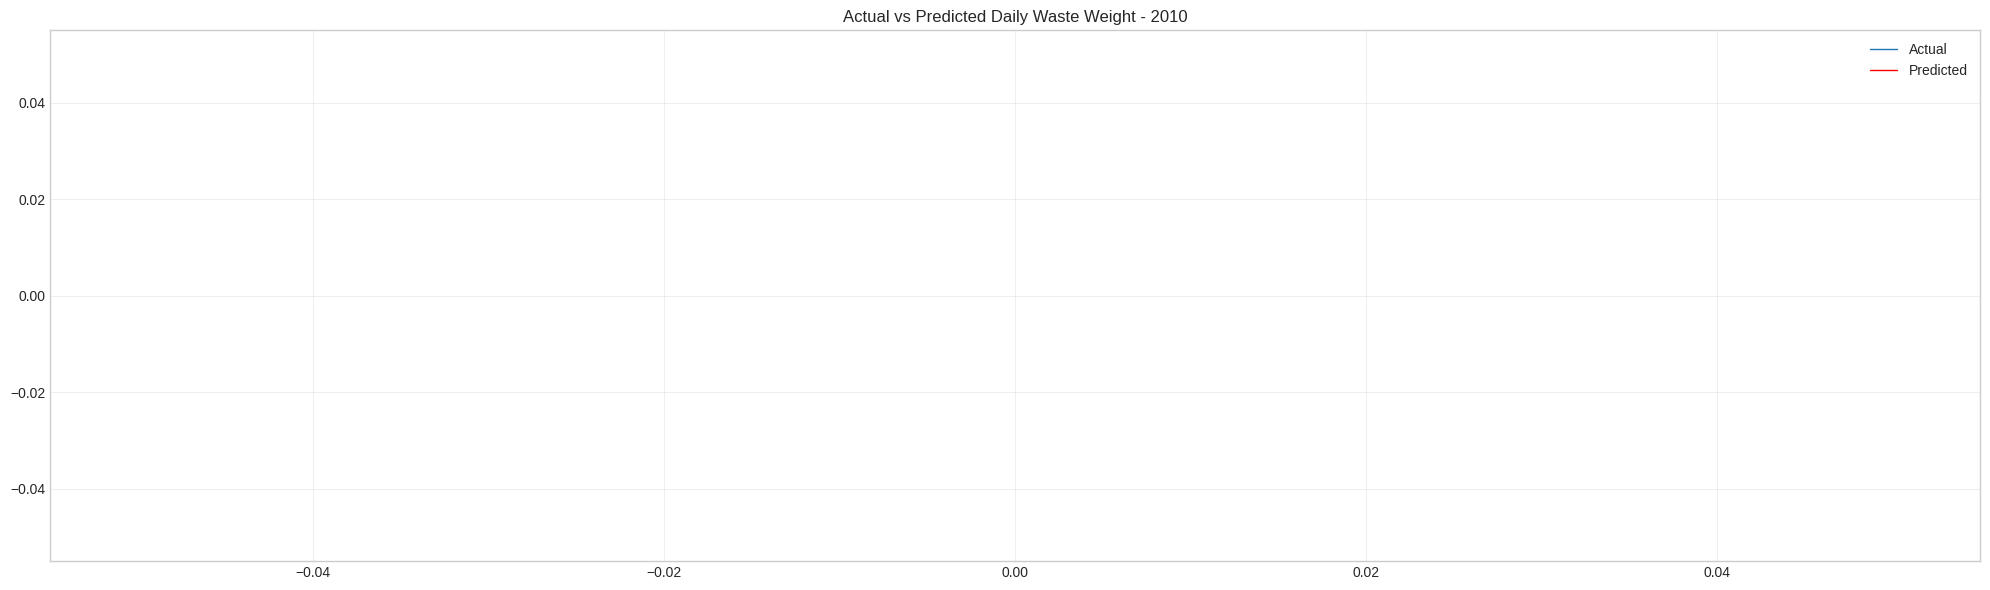

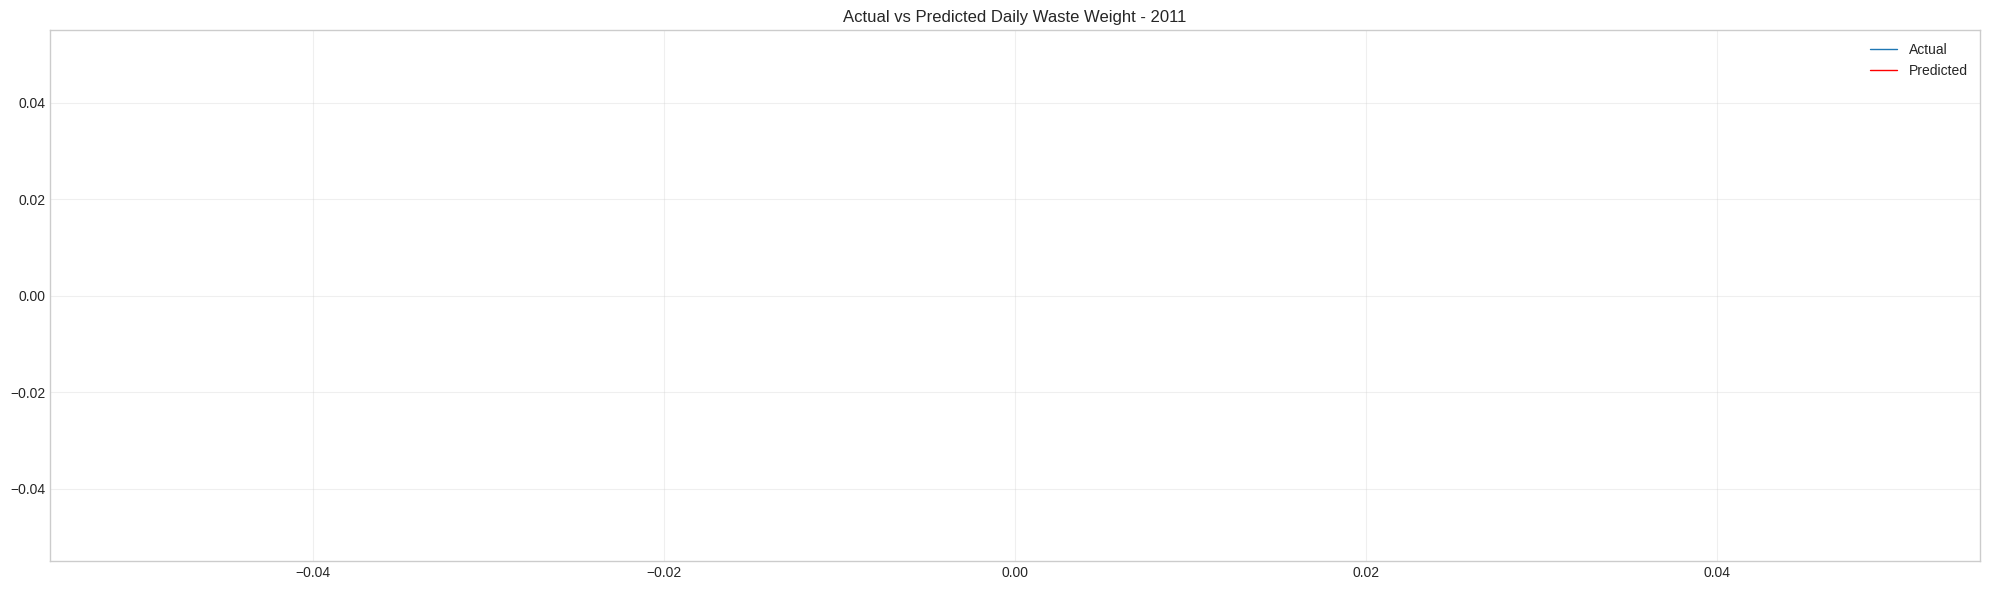

In [66]:
plt.figure(figsize=(20, 6))
plt.plot(df['ticket_date'], df['net_weight_kg'], label='Actual / stored values', linewidth=1)
plt.plot(df['ticket_date'], df['predicted_net_weight_kg'], color='red', label='Predicted values', linewidth=1)
plt.title('Actual and Predicted Daily Waste Weight')
plt.xlabel('Ticket date'); plt.ylabel('Net weight (kg)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


In [67]:
df_backup = df.copy()

In [68]:
del df['predicted_net_weight_kg']

In [69]:
df.columns

Index(['ticket_date', 'net_weight_kg'], dtype='object')

In [70]:
df.to_csv("daily_waste_output_Dehiwala.csv", index=False)
print("File saved: daily_waste_output_Dehiwala.csv")

File saved: daily_waste_output_Dehiwala.csv
